# EcoLar · 01 / Previsão do consumo do próximo dia
**Equipe:** Yan Almeida RM568814 · Vinicius Pacheco Ruiz RM571109 · Diego Barbosa RM568829.
Turma 1TDSPV. Experimento executável para Artificial Intelligence & Chatbot.

**Pergunta:** sete consumos diários anteriores e o calendário ajudam a estimar o próximo dia?
Modelo: RandomForestRegressor. Comparação com último dia, mesma data da semana anterior
e média móvel de sete dias. Métricas em kWh: MAE e RMSE; R² como medida adicional.
Use **Run All / Executar Tudo** com o kernel da `.venv`.

## Fonte, transformação e limites
Hebrail e Berard, **Individual Household Electric Power Consumption**, UCI, DOI
[10.24432/C58K54](https://doi.org/10.24432/C58K54), CC BY 4.0.
Uma residência francesa, medições de minuto em 2006–2010. A energia diária é
`soma(Global_active_power) / 60`, pois a potência está em kW e cada leitura representa um minuto.
Só entram dias com 1.440 minutos válidos. Não dividimos conta mensal por 30, não preenchemos
ausências com zero e não usamos os dados simulados do Oracle para treinar.

Os CSVs derivados utilizados no treinamento já estão incluídos em `dados/`.
`preparar_dados.py` reproduz a derivação a partir do download oficial; o arquivo
`dados/fonte.json` registra origem, regra e SHA-256 do ZIP original.
**Este experimento não comprova desempenho em outras casas ou no Brasil.**

In [1]:
from pathlib import Path
import sys, os, json
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '2')
raiz = Path.cwd()
if not (raiz / 'ecolar_ia').exists(): raiz = raiz.parent
assert (raiz / 'ecolar_ia').exists(), 'Abra a pasta EcoLar_IA no VS Code.'
sys.path.insert(0, str(raiz))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display, Markdown
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error
from ecolar_ia import VERSAO
from ecolar_ia.dados import RAIZ, carregar_diario
from ecolar_ia.features import COLUNAS_REGRESSAO, COLUNAS_GRUPO, tabela_regressao, tabela_grupos
from ecolar_ia.treino import salvar_json, metricas_regressao, qualidade_grupos, registrar_ambiente
plt.rcParams.update({'figure.figsize':(10,4), 'axes.spines.top':False, 'axes.spines.right':False})
figuras = RAIZ / 'resultados/graficos'
figuras.mkdir(parents=True, exist_ok=True)
diario = carregar_diario()
display(diario.head())

,data,consumo_kwh
0,2006-12-17,56.507667
1,2006-12-18,36.730433
2,2006-12-19,27.769900
3,2006-12-20,37.095800
4,2006-12-22,39.022300


## 1. Análise exploratória e controle de qualidade

fonte                  UCI Individual Household Electric Power Consum...
url                    https://archive.ics.uci.edu/static/public/235/...
doi                                                      10.24432/C58K54
licenca                                                        CC BY 4.0
autores                                   Georges Hebrail e Alice Berard
consulta                                                      2026-11-11
sha256_zip_original    9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263...
linhas_minuto                                                    2075259
dias_calendario                                                     1442
dias_completos                                                      1358
dias_excluidos                                                        84
periodo_original              [2006-12-16 17:24:00, 2010-11-26 21:02:00]
regra                  Somar Global_active_power / 60 por dia; aceita...
limite                 Uma casa francesa de 2006-20

,kWh/dia
count,1358.000000
mean,25.976880
std,9.927523
min,4.171633
25%,19.431908
50%,25.579633
75%,31.453767
max,79.556433


dia_completo
False      84
True     1358
Name: quantidade_dias, dtype: int64

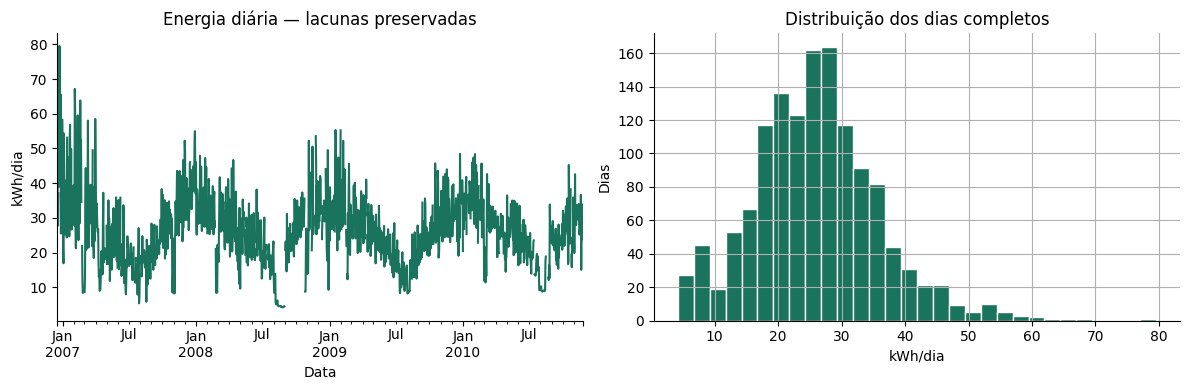

In [2]:
auditoria = pd.read_csv(RAIZ / 'dados/auditoria_diaria.csv', parse_dates=['data'])
display(pd.Series(json.loads((RAIZ/'dados/fonte.json').read_text(encoding='utf-8'))))
display(diario.consumo_kwh.describe().to_frame('kWh/dia'))
display(auditoria.groupby('dia_completo').size().rename('quantidade_dias'))
assert not diario.data.duplicated().any()
assert diario.consumo_kwh.ge(0).all()
fig, ax = plt.subplots(1,2,figsize=(12,4))
auditoria.plot(x='data',y='consumo_kwh',ax=ax[0],color='#19735d',legend=False)
ax[0].set(title='Energia diária — lacunas preservadas',xlabel='Data',ylabel='kWh/dia')
diario.consumo_kwh.hist(ax=ax[1],bins=30,color='#19735d',edgecolor='white')
ax[1].set(title='Distribuição dos dias completos',xlabel='kWh/dia',ylabel='Dias')
fig.tight_layout(); fig.savefig(figuras/'01_analise_exploratoria.png',dpi=150); plt.show()

## 2. Preparação e avaliação temporal
Cada amostra usa sete dias consecutivos como entrada e o oitavo como alvo. `lag_7` é o mais antigo;
`lag_1`, o último observado. Calendário cíclico é conhecido na data da previsão.
Só criamos amostras se todos os oito dias estiverem disponíveis. O teste final é o último 20% das
amostras. No desenvolvimento (primeiro 80%), reservamos o trecho final para escolher quatro
configurações; só depois reajustamos no desenvolvimento inteiro e avaliamos uma vez no teste.

Avaliação **um passo à frente**: dias já observados do período de teste podem ser entradas de
previsões posteriores. Isso não é uma previsão recursiva de vários meses sem novas observações.
Não há embaralhamento. Resultado de teste não é usado para selecionar hiperparâmetros.

In [3]:
amostras = tabela_regressao(diario)
display(amostras.head())
display(amostras[COLUNAS_REGRESSAO+['alvo_kwh']].corr().round(2))
print('Dias completos:',len(diario),'| Janelas com alvo:',len(amostras))

,data_alvo,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1,dia_semana_seno,dia_semana_cosseno,mes_seno,mes_cosseno,alvo_kwh
0,2006-12-29,39.022300,79.556433,42.500200,45.718667,65.568500,25.479333,34.543967,-0.433884,-0.900969,-0.5,0.866025,52.906533
1,2007-01-07,58.236600,45.816733,21.153933,16.900900,54.323533,45.222733,25.139633,-0.781831,0.623490,0.0,1.000000,40.793667
2,2007-01-08,45.816733,21.153933,16.900900,54.323533,45.222733,25.139633,40.793667,0.000000,1.000000,0.0,1.000000,37.356000
3,2007-01-09,21.153933,16.900900,54.323533,45.222733,25.139633,40.793667,37.356000,0.781831,0.623490,0.0,1.000000,31.150900
4,2007-01-10,16.900900,54.323533,45.222733,25.139633,40.793667,37.356000,31.150900,0.974928,-0.222521,0.0,1.000000,35.913333


,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1,dia_semana_seno,dia_semana_cosseno,mes_seno,mes_cosseno,alvo_kwh
lag_7,1.00,0.63,0.49,0.56,0.56,0.47,0.51,-0.15,0.02,0.07,0.56,0.59
lag_6,0.63,1.00,0.63,0.49,0.58,0.56,0.48,-0.11,-0.13,0.06,0.57,0.51
lag_5,0.49,0.63,1.00,0.63,0.49,0.57,0.58,0.01,-0.16,0.07,0.58,0.49
lag_4,0.56,0.49,0.63,1.00,0.62,0.49,0.57,0.12,-0.10,0.07,0.58,0.57
lag_3,0.56,0.58,0.49,0.62,1.00,0.62,0.51,0.14,0.02,0.06,0.60,0.58
lag_2,0.47,0.56,0.57,0.49,0.62,1.00,0.63,0.07,0.12,0.06,0.61,0.51
lag_1,0.51,0.48,0.58,0.57,0.51,0.63,1.00,-0.03,0.11,0.05,0.63,0.61
dia_semana_seno,-0.15,-0.11,0.01,0.12,0.14,0.07,-0.03,1.00,0.01,0.02,0.00,-0.10
dia_semana_cosseno,0.02,-0.13,-0.16,-0.10,0.02,0.12,0.11,0.01,1.00,0.00,-0.01,0.04
mes_seno,0.07,0.06,0.07,0.07,0.06,0.06,0.05,0.02,0.00,1.00,0.02,0.03


Dias completos: 1358 | Janelas com alvo: 909


## 3. Treinamento, avaliação e exportação
Código abaixo é a implementação de `ecolar_ia/treino.py`, mantida também em módulo para
`python treinar.py`. O CSV exportado identifica a partição de cada amostra; o teste não entra no fit.

In [4]:
tabela = tabela_regressao(carregar_diario())
corte = int(len(tabela) * .8)
desenvolvimento, teste = tabela.iloc[:corte], tabela.iloc[corte:]
corte_interno = int(len(desenvolvimento) * .8)
treino, validacao = desenvolvimento.iloc[:corte_interno], desenvolvimento.iloc[corte_interno:]
candidatos = []
# Ajuste pequeno, determinado antes de olhar o teste final.
for profundidade, folha in [(4,5), (8,5), (None,5), (8,10)]:
    modelo = RandomForestRegressor(n_estimators=160, max_depth=profundidade,
                                  min_samples_leaf=folha, random_state=42, n_jobs=1)
    modelo.fit(treino[COLUNAS_REGRESSAO], treino.alvo_kwh)
    mae = mean_absolute_error(validacao.alvo_kwh, modelo.predict(validacao[COLUNAS_REGRESSAO]))
    candidatos.append({"max_depth":profundidade, "min_samples_leaf":folha, "mae_validacao_kwh":float(mae)})
melhor = min(candidatos, key=lambda r:r["mae_validacao_kwh"])
modelo = RandomForestRegressor(n_estimators=160, max_depth=melhor["max_depth"],
                              min_samples_leaf=melhor["min_samples_leaf"], random_state=42, n_jobs=1)
modelo.fit(desenvolvimento[COLUNAS_REGRESSAO], desenvolvimento.alvo_kwh)
previsto = modelo.predict(teste[COLUNAS_REGRESSAO])
referencias = {"ultimo_dia":teste.lag_1.to_numpy(),
               "mesmo_dia_semana_anterior":teste.lag_7.to_numpy(),
               "media_7_dias":teste[COLUNAS_REGRESSAO[:7]].mean(axis=1).to_numpy()}
avaliacao = {"modelo":"RandomForestRegressor", "unidade":"kWh/dia", "versao":VERSAO,
            "amostras":len(tabela), "amostras_treino_final":len(desenvolvimento),
            "amostras_teste":len(teste), "selecao_hiperparametros":candidatos,
            "parametros_escolhidos":melhor,
            "periodo_treino":[str(desenvolvimento.data_alvo.min().date()),str(desenvolvimento.data_alvo.max().date())],
            "periodo_teste":[str(teste.data_alvo.min().date()),str(teste.data_alvo.max().date())],
            "teste_modelo":metricas_regressao(teste.alvo_kwh, previsto),
            "teste_baselines":{k:metricas_regressao(teste.alvo_kwh,v) for k,v in referencias.items()},
            "metodo":"Holdout cronológico 80/20. Hiperparâmetros selecionados em holdout interno 80/20 do desenvolvimento. Teste final nunca entra no fit.",
            "limite":"Teste em período posterior da mesma casa; não mede desempenho em outras casas ou no Brasil."}
tabela["particao"] = ["treino" if i < corte else "teste" for i in range(len(tabela))]
tabela.to_csv(RAIZ / "dados/treinamento_regressao.csv", index=False)
resultado = teste[["data_alvo","alvo_kwh"]].copy()
resultado["previsto_kwh"] = previsto
for nome,v in referencias.items(): resultado[nome] = v
(RAIZ / "resultados").mkdir(exist_ok=True)
resultado.to_csv(RAIZ / "resultados/previsoes_teste.csv", index=False)
salvar_json(RAIZ / "resultados/metricas_regressao.json", avaliacao)
bundle = {"modelo":modelo, "colunas":COLUNAS_REGRESSAO, "versao":VERSAO,
          "sklearn":sklearn.__version__, "tipo":"regressao", "avaliacao":avaliacao,
          "faixa_diaria_treino":[float(desenvolvimento[COLUNAS_REGRESSAO[:7]].min().min()),
                                  float(desenvolvimento[COLUNAS_REGRESSAO[:7]].max().max())]}
(RAIZ / "modelos").mkdir(exist_ok=True)
joblib.dump(bundle, RAIZ / "modelos/previsao.joblib", compress=3)

['C:\\Users\\yanal\\Downloads\\EcoLar_IA_Projeto\\EcoLar_IA\\modelos\\previsao.joblib']

In [5]:
display(pd.DataFrame(avaliacao['selecao_hiperparametros']))
comparacao = pd.DataFrame({'Random Forest':avaliacao['teste_modelo'],**avaliacao['teste_baselines']}).T
display(comparacao.round(4))
print('Treino:',avaliacao['periodo_treino'],'| Teste:',avaliacao['periodo_teste'])

,max_depth,min_samples_leaf,mae_validacao_kwh
0,4.0,5,4.950293
1,8.0,5,4.925108
2,NaN,5,4.957638
3,8.0,10,4.880911


,mae_kwh,rmse_kwh,r2
Random Forest,3.8938,5.2939,0.4844
ultimo_dia,4.5524,6.4734,0.2290
mesmo_dia_semana_anterior,5.4883,7.4142,-0.0114
media_7_dias,3.8808,5.4575,0.4520


Treino: ['2006-12-29', '2010-03-07'] | Teste: ['2010-03-08', '2010-11-25']


## 4. Resultados e interpretação crítica

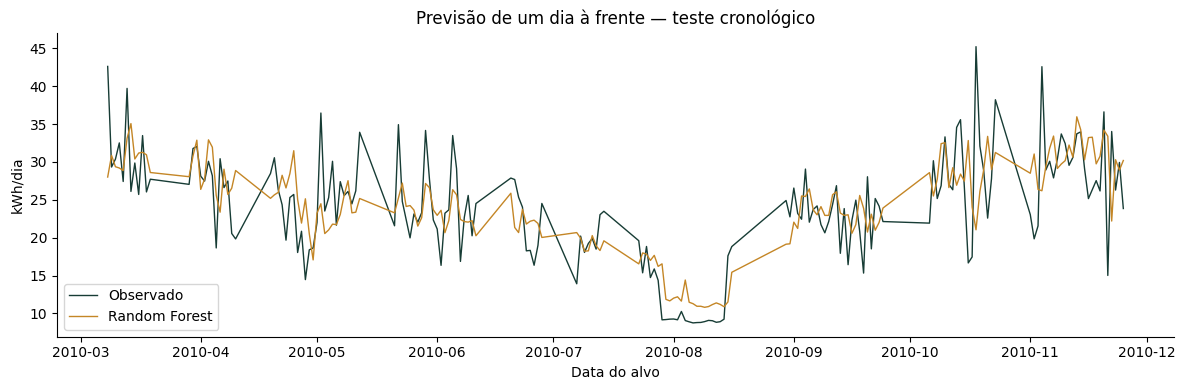

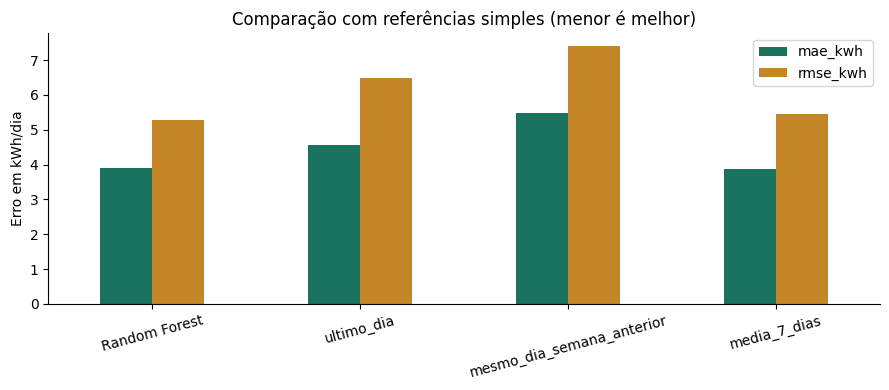

MAE Random Forest: **3.894 kWh**; média de sete dias: **3.881 kWh**. O modelo não deve ser declarado superior em todas as métricas. Avaliar também RMSE, variação temporal e custo de complexidade. Não ajustamos novamente usando o teste para tentar melhorar essa comparação.

In [6]:
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(resultado.data_alvo,resultado.alvo_kwh,label='Observado',color='#173c35',linewidth=1)
ax.plot(resultado.data_alvo,resultado.previsto_kwh,label='Random Forest',color='#c48626',linewidth=1)
ax.set(title='Previsão de um dia à frente — teste cronológico',xlabel='Data do alvo',ylabel='kWh/dia')
ax.legend();fig.tight_layout();fig.savefig(figuras/'02_regressao_teste.png',dpi=150);plt.show()
fig,ax=plt.subplots(figsize=(9,4))
comparacao[['mae_kwh','rmse_kwh']].plot.bar(ax=ax,color=['#19735d','#c48626'])
ax.set(title='Comparação com referências simples (menor é melhor)',ylabel='Erro em kWh/dia',xlabel='')
ax.tick_params(axis='x',rotation=15)
fig.tight_layout();fig.savefig(figuras/'03_baselines.png',dpi=150);plt.show()
mae=avaliacao['teste_modelo']['mae_kwh']
mae_media=avaliacao['teste_baselines']['media_7_dias']['mae_kwh']
display(Markdown(f'MAE Random Forest: **{mae:.3f} kWh**; média de sete dias: **{mae_media:.3f} kWh**. '
 'O modelo não deve ser declarado superior em todas as métricas. Avaliar também RMSE, variação temporal e custo de complexidade. '
 'Não ajustamos novamente usando o teste para tentar melhorar essa comparação.'))

## 5. Uso no EcoLar, limitações e próxima revisão
O arquivo `modelos/previsao.joblib` contém o estimador, ordem de atributos, versão e métricas.
A API `/prever` reutiliza as mesmas funções de transformação. MAE é erro médio absoluto, não
uma probabilidade de acerto; não devolveremos "precisão de 95%" nem intervalo sem calibração.

São 909 janelas da mesma residência, com exclusão de dias incompletos. Sazonalidade, ocupação,
clima e mudanças de hábitos limitam a transferência. A exclusão pode enviesar a amostra.
Para evoluir: dados locais de várias casas, mais validação temporal e análise de falhas sazonais,
sem usar repetidamente o mesmo teste como conjunto de ajuste.

Fontes: [UCI](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption),
[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html),
[persistência](https://scikit-learn.org/stable/model_persistence.html). Consulta 11/11/2026.

In [7]:
registrar_ambiente()
print('Exportação concluída:',RAIZ/'modelos/previsao.joblib')

Exportação concluída: C:\Users\yanal\Downloads\EcoLar_IA_Projeto\EcoLar_IA\modelos\previsao.joblib
